# 03. Качество данных и оптимизация LightGBM

**Цель:** улучшить модель из ноутбука 02 (LightGBM, WAPE 23,4% на test) и понять, где она ошибается.

**План:**
1. **Качество данных** — пропуски, дубликаты, выбросы в исходных транзакциях и в `daily.parquet`. Каждое решение по очистке — с обоснованием.
2. **Новые признаки:** «день месяца» и «выдача 28 дней назад».
3. **Optuna** — подбор параметров LightGBM. Валидация — **май–июнь 2025**, test не трогаем.
4. **Сравнение на test:** baseline → LightGBM до → LightGBM после. Отдельно: сколько дали признаки, а сколько Optuna.
5. **Разбор ошибок:** типы банкоматов, дни недели, месяцы, особые дни — и почему так.
6. **Сохранение** лучшей модели и списка признаков в `models/`.

**Правило честной проверки:** всё, что подбирается (признаки, очистка, параметры, число деревьев), решается **только по валидации** (май–июнь 2025). Test (июль–декабрь 2025) открываем один раз, в разделе 4.

In [1]:
from pathlib import Path
import json, platform
import duckdb
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import optuna
import pandas as pd
import sklearn

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "mbank-atm-bishkek"
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2,
})
thousands = mticker.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}".replace(",", " "))
pct0 = mticker.PercentFormatter(1.0, decimals=0)
fmt_int = lambda v: f"{v:,.0f}".replace(",", " ")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

SEED = 42
TRAIN_END = pd.Timestamp("2025-06-30")
VAL_START = pd.Timestamp("2025-05-01")   # валидация: май–июнь 2025 (последние 2 месяца train)
TEST_START = pd.Timestamp("2025-07-01")
TARGET = "cash_out"

df = pd.read_parquet(ROOT / "data" / "processed" / "daily.parquet")
df = df.sort_values(["atm_id", "date"]).reset_index(drop=True)
print(df.shape, df.date.min().date(), "…", df.date.max().date())
print("lightgbm", lgb.__version__, "| optuna", optuna.__version__)

(82565, 39) 2024-01-01 … 2025-12-31
lightgbm 4.7.0 | optuna 5.0.0


## 1. Качество данных

Проверяем два уровня:
- **исходные транзакции** (`fact_transactions`, 12,5 млн строк) — из них в ноутбуке 01 собрана целевая переменная;
- **таблица «банкомат × день»** (`daily.parquet`) — то, на чём учится модель.

### 1.1 Исходные транзакции

In [2]:
con = duckdb.connect()
con.sql(f"CREATE VIEW tx AS SELECT * FROM read_parquet('{RAW}/facts/fact_transactions/**/*.parquet', hive_partitioning = true)")
con.sql(f"CREATE VIEW atm AS SELECT * FROM read_parquet('{RAW}/dimensions/dim_atm.parquet')")
one = lambda sql: con.sql(sql).df().iat[0, 0]
CASH = "txn_type IN ('withdrawal', 'fast_cash')"

raw_checks = pd.Series({
    "транзакций": one("SELECT count(*) FROM tx"),
    "уникальных txn_id": one("SELECT count(DISTINCT txn_id) FROM tx"),
    "полных дублей (банкомат + время + карта + тип + сумма)": one(
        "SELECT count(*) FROM (SELECT 1 FROM tx GROUP BY atm_id, timestamp, card_id, txn_type, requested_amount HAVING count(*) > 1)"),
    "RRN повторяется (у разных карт)": one(
        "SELECT count(*) FROM (SELECT rrn FROM tx GROUP BY rrn HAVING count(*) > 1 AND count(DISTINCT card_id) > 1)"),
    "RRN повторяется (у одной карты)": one(
        "SELECT count(*) FROM (SELECT rrn FROM tx GROUP BY rrn HAVING count(*) > 1 AND count(DISTINCT card_id) = 1)"),
    "выдано больше, чем запрошено": one("SELECT count(*) FROM tx WHERE dispensed_amount > requested_amount"),
    "отрицательные суммы": one("SELECT count(*) FROM tx WHERE dispensed_amount < 0 OR requested_amount < 0"),
    "деньги выданы при отказе (is_approved = false)": one("SELECT count(*) FROM tx WHERE dispensed_amount > 0 AND NOT is_approved"),
    "сумма выдачи не кратна 100 сом": one(f"SELECT count(*) FROM tx WHERE {CASH} AND dispensed_amount % 100 <> 0"),
    "выдача больше лимита одной операции": one(
        "SELECT count(*) FROM tx JOIN atm USING (atm_id) WHERE dispensed_amount > txn_limit"),
    "банкомат не найден в справочнике": one("SELECT count(*) FROM tx WHERE atm_id NOT IN (SELECT atm_id FROM atm)"),
    "операции раньше даты установки банкомата": one(
        "SELECT count(*) FROM tx JOIN atm USING (atm_id) WHERE timestamp < install_date"),
    "дата не совпадает с timestamp": one("SELECT count(*) FROM tx WHERE CAST(timestamp AS DATE) <> CAST(date AS DATE)"),
})
print(raw_checks.map(fmt_int).to_string())

cols = con.sql("DESCRIBE tx").df()["column_name"].tolist()
na = con.sql("SELECT " + ", ".join(f"count(*) - count({c}) AS na_{c}" for c in cols) + " FROM tx").df().iloc[0]
na.index = cols
print("\nПропуски (только колонки, где они есть):"); print(na[na > 0].map(fmt_int).to_string())
print("customer_id пустой только у чужих карт (off-us):",
      one("SELECT count(*) FROM tx WHERE (customer_id IS NULL) <> (NOT is_on_us)") == 0)

print("\nОперация до установки банкомата:")
print(con.sql("SELECT txn_id, atm_id, timestamp, txn_type, dispensed_amount, install_date "
              "FROM tx JOIN atm USING (atm_id) WHERE timestamp < install_date").df().to_string(index=False))

транзакций                                                12 561 940
уникальных txn_id                                         12 561 940
полных дублей (банкомат + время + карта + тип + сумма)             0
RRN повторяется (у разных карт)                                   90
RRN повторяется (у одной карты)                                    0
выдано больше, чем запрошено                                       0
отрицательные суммы                                                0
деньги выданы при отказе (is_approved = false)                     0
сумма выдачи не кратна 100 сом                                     0
выдача больше лимита одной операции                                0
банкомат не найден в справочнике                                   0
операции раньше даты установки банкомата                           1
дата не совпадает с timestamp                                      0



Пропуски (только колонки, где они есть):
customer_id    2 793 660
customer_id пустой только у чужих карт (off-us): True

Операция до установки банкомата:
  txn_id   atm_id           timestamp   txn_type  dispensed_amount install_date
12561907 ATM-0056 2024-02-10 19:00:00 withdrawal              3000   2024-11-06


In [3]:
by_type = con.sql("""
    SELECT txn_type, count(*) AS n, sum(dispensed_amount) AS dispensed_amount
    FROM tx GROUP BY 1 ORDER BY 2 DESC""").df().set_index("txn_type")
print("Типы операций и поле dispensed_amount:")
print(by_type.assign(dispensed_amount=lambda d: (d.dispensed_amount / 1e6).round(1)).rename(
    columns={"dispensed_amount": "dispensed_amount, млн"}).to_string())

codes = con.sql("""
    SELECT response_code, any_value(is_approved) AS approved, count(*) AS n,
           sum(dispensed_amount) AS dispensed
    FROM tx GROUP BY 1 ORDER BY 1""").df()
codes["доля"] = (codes.n / codes.n.sum()).map("{:.2%}".format)
print("\nКоды ответа:"); print(codes.to_string(index=False))

fraud = con.sql(f"""
    SELECT f.kind, count(*) AS n, sum(t.dispensed_amount) AS dispensed
    FROM read_parquet('{RAW}/labels/fraud.parquet') f JOIN tx t USING (txn_id) GROUP BY 1""").df()
total_cash = one(f"SELECT sum(dispensed_amount) FROM tx WHERE {CASH}")
print("\nМошеннические операции (метки датасета):"); print(fraud.to_string(index=False))
print(f"Доля мошенничества в выдаче: {fraud.dispensed.sum() / total_cash:.3%}")

print(f"\nСверка: сумма выдачи в транзакциях {total_cash/1e9:.3f} млрд, "
      f"в daily.parquet {df.cash_out.sum()/1e9:.3f} млрд")

Типы операций и поле dispensed_amount:
                       n  dispensed_amount, млн
txn_type                                       
withdrawal       8792312                36801.5
fast_cash        1507593                 6303.3
balance_inquiry  1130598                    0.0
transfer          503830                    0.0
mini_statement    502259                    0.0
deposit           125348                  524.5

Коды ответа:
response_code  approved        n    dispensed   доля
           00      True 11708966 4.362933e+10 93.21%
           51     False   351067 0.000000e+00  2.79%
           55     False   250900 0.000000e+00  2.00%
           91     False   106215 0.000000e+00  0.85%
           92     False    81385 0.000000e+00  0.65%
           94     False    37725 0.000000e+00  0.30%
           96     False     6340 0.000000e+00  0.05%
           99     False    19342 0.000000e+00  0.15%

Мошеннические операции (метки датасета):
        kind   n  dispensed
    skimming 216

**Выводы и решения по транзакциям:**

| Что нашли | Решение | Почему |
|---|---|---|
| Дублей нет: все 12,56 млн `txn_id` уникальны, полных повторов (банкомат + время + карта + тип + сумма) — 0 | ничего не делаем | чистить нечего |
| 90 повторяющихся номеров RRN | **оставляем** | у каждой пары **разные карты**, суммы и время — это случайные совпадения 12-значного номера, а не двойная запись одной операции |
| Пропуски только в `customer_id` (2,8 млн) | **оставляем** | пусто ровно у чужих карт (off-us) — так и задумано: у банка нет данных о чужих клиентах. Для выдачи наличных это поле не нужно |
| Код `94` «дубликат операции» (37 тыс.) | ничего не делаем | это отказы, денег по ним выдано 0 — на сумму выдачи не влияют |
| У `deposit` заполнено `dispensed_amount` (524 млн сом) | **не считаем выдачей** (так уже сделано в 01) | это внесённые деньги, а не выданные; выдачу считаем только по `withdrawal` и `fast_cash` |
| Нарушений логики нет: выдано ≤ запрошено, нет отрицательных сумм, нет выдачи при отказе, нет сумм больше лимита, все суммы кратны 100 | ничего не делаем | данные согласованы |
| 1 операция ATM-0056 за 10.02.2024 — **за 9 месяцев до установки** банкомата (06.11.2024), 3 000 сом | **исключаем** (уже исключена: сетка дней в 01 начинается с даты установки) | банкомат физически ещё не стоял — это ошибка записи |
| Мошенничество (скимминг и «невозможные перемещения») — 256 операций, 0,011% выдачи | **оставляем в выдаче** | деньги физически ушли из банкомата; для планирования инкассации важна именно сумма, вынутая из кассет. Влияние на модель — нулевое |

Сверка: сумма выдачи в транзакциях и в `daily.parquet` совпадает (43,105 млрд сом) — при агрегации ничего не потерялось.

### 1.2 Таблица «банкомат × день» (`daily.parquet`)

In [4]:
install = df.groupby("atm_id").install_date.first()
expected_days = (df.date.max() - install.clip(lower=df.date.min())).dt.days + 1   # сетка начинается с 01.01.2024 или с даты установки
missing_days = (expected_days - df.groupby("atm_id").size()).sum()

daily_checks = pd.Series({
    "строк": fmt_int(len(df)),
    "банкоматов": df.atm_id.nunique(),
    "дубликатов (atm_id, date)": df.duplicated(["atm_id", "date"]).sum(),
    "пропущенных дней в сетке (после установки)": missing_days,
    "отрицательная выдача": (df.cash_out < 0).sum(),
    "дней с нулевой выдачей": (df.cash_out == 0).sum(),
    "  из них со сбоем": (df.cash_out.eq(0) & df.is_disrupted).sum(),
    "дней со сбоем (пустой / простой)": f"{df.is_disrupted.sum()} ({df.is_disrupted.mean():.2%})",
    "банкоматов, установленных внутри периода": (install > df.date.min()).sum(),
})
print(daily_checks.to_string())

na = df.isna().sum()
print("\nПропуски по колонкам:"); print(na[na > 0].to_string())
print("\nСтроки с пропуском decline_share:")
print(df.loc[df.decline_share.isna(), ["atm_id", "date", "n_txn", "cash_out", "is_disrupted", "down_hours"]].to_string(index=False))

cold = install[install > df.date.min()].sort_values()
print("\nНовые банкоматы (дата установки):")
print(cold.dt.date.to_frame().join(df.groupby("atm_id").atm_type.first()).to_string())

строк                                               82 565
банкоматов                                             120
дубликатов (atm_id, date)                                0
пропущенных дней в сетке (после установки)               0
отрицательная выдача                                     0
дней с нулевой выдачей                                   8
  из них со сбоем                                        0
дней со сбоем (пустой / простой)              1077 (1.30%)
банкоматов, установленных внутри периода                14

Пропуски по колонкам:
decline_share        3
holiday_name     78319

Строки с пропуском decline_share:
  atm_id       date  n_txn  cash_out  is_disrupted  down_hours
ATM-0039 2024-01-07      0       0.0         False         0.0
ATM-0090 2024-04-07      0       0.0         False         0.0
ATM-0101 2024-01-07      0       0.0         False         0.0

Новые банкоматы (дата установки):
         install_date          atm_type
atm_id                                

**Выводы и решения по таблице «банкомат × день»:**

| Что нашли | Решение | Почему |
|---|---|---|
| Дублей (банкомат, дата) нет, пропущенных дней в сетке нет | ничего не делаем | каждый банкомат представлен каждым днём с момента установки |
| Пропуски в `holiday_name` (78 тыс.) | **оставляем** | в обычный день праздника нет — это не пропуск, а «нет значения». Модель использует флаг `is_holiday`, а не название |
| 3 пропуска в `decline_share` | **оставляем**, признак в модели не используется | это дни, когда операций не было вообще (делить на ноль нельзя) |
| 8 дней с нулевой выдачей, все без отмеченного сбоя | **оставляем** | все 8 — **офисные банкоматы в праздник, выпавший на выходной** (Рождество, День независимости и др.): офис закрыт, клиентов нет. Это настоящий спрос, а не потеря данных |
| 1 077 дней сбоя (1,3%): банкомат пустой или в простое | **исключаем из обучения и основной оценки, считаем отдельно** (как в 02) | в эти дни мы видим не спрос, а то, что банкомат *успел* выдать. Учить на этом модель — значит учить её занижать пики |
| 14 банкоматов установлены внутри периода (последний — 13.08.2025, уже в test) | **оставляем** | в реальности новые банкоматы будут появляться; первые дни без истории отсекаются сами (нет лагов), дальше модель работает как обычно. В разделе 5 проверим, хуже ли она на них |

### 1.3 Выбросы

Банкоматы очень разные по масштабу, поэтому один общий порог для всех («больше 2 млн — выброс») не годится. Для каждого банкомата и дня считаем **обычный уровень** — медиану выдачи за ±2 недели (без дней сбоев) — и смотрим **во сколько раз** день от него отличается.
- **Высокий выброс:** выдача больше обычного уровня в 2,5 раза и больше.
- **Низкий выброс:** меньше 30% от обычного уровня.

Главный вопрос: это **ошибки данных** или **настоящий спрос** (пенсии, праздники, скачки курса)?

In [5]:
clean_cash = df.cash_out.where(~df.is_disrupted)
df["ref_med"] = clean_cash.groupby(df.atm_id).transform(lambda s: s.rolling(29, center=True, min_periods=10).median())
df["ratio"] = df.cash_out / df.ref_med
ok = ~df.is_disrupted & df.ref_med.gt(0)
df["outlier"] = np.select([ok & (df.ratio >= 2.5), ok & (df.ratio < 0.3)], ["высокий", "низкий"], "")

out = df[df.outlier != ""]
print(f"Высоких выбросов: {(df.outlier == 'высокий').sum()} ({(df.outlier == 'высокий').sum() / ok.sum():.2%} дней)")
print(f"Низких выбросов:  {(df.outlier == 'низкий').sum()} ({(df.outlier == 'низкий').sum() / ok.sum():.2%} дней)")

special = df.is_pension_day | df.is_payday | df.is_holiday | df.is_pre_holiday | df.fx_shock
print(f"\nДоля особых дней (пенсия / зарплата / праздник / предпраздник / скачок курса):")
print(f"  среди всех дней        {special[ok].mean():.0%}")
print(f"  среди высоких выбросов {special[df.outlier == 'высокий'].mean():.0%}")
print(f"  среди низких выбросов  {special[df.outlier == 'низкий'].mean():.0%}")

print("\nВысокие выбросы по типу точки (доля дней этого типа):")
print((df[ok].groupby("atm_type").outlier.apply(lambda s: (s == "высокий").mean()) * 100).round(2).sort_values(ascending=False).to_string())

flag_cols = {"is_pension_day": "пенсия", "is_payday": "зарплата", "is_holiday": "праздник",
             "is_pre_holiday": "предпраздник", "fx_shock": "скачок курса", "is_weekend": "выходной"}
hi = df[df.outlier == "высокий"]
print("\nКакие флаги стоят у высоких выбросов (доля):")
print(pd.Series({v: hi[k].mean() for k, v in flag_cols.items()}).map("{:.0%}".format).to_string())
lo = df[df.outlier == "низкий"]
print("\nНизкие выбросы: тип точки и выходной")
print(lo.groupby(["atm_type", "is_weekend"]).size().sort_values(ascending=False).head(6).to_string())
print("\nСамые большие отношения к обычному уровню:")
print(df.loc[ok].nlargest(8, "ratio")[["atm_id", "date", "atm_type", "cash_out", "ref_med", "ratio",
                                        "is_pension_day", "is_payday", "fx_shock"]].round({"ratio": 2}).to_string(index=False))

Высоких выбросов: 2630 (3.23% дней)
Низких выбросов:  2471 (3.03% дней)

Доля особых дней (пенсия / зарплата / праздник / предпраздник / скачок курса):
  среди всех дней        33%
  среди высоких выбросов 92%
  среди низких выбросов  32%

Высокие выбросы по типу точки (доля дней этого типа):


atm_type
pension_social      10.49
office_business      7.11
shopping_mall        2.31
residential          1.00
tourist_center       0.98
transport_market     0.91
highway_gas          0.43

Какие флаги стоят у высоких выбросов (доля):
пенсия          67%
зарплата        82%
праздник         1%
предпраздник     9%
скачок курса     2%
выходной        25%

Низкие выбросы: тип точки и выходной
atm_type         is_weekend
office_business  True          1862
                 False          319
pension_social   False           81
                 True            64
shopping_mall    False           52
residential      False           31

Самые большие отношения к обычному уровню:
  atm_id       date        atm_type  cash_out  ref_med  ratio  is_pension_day  is_payday  fx_shock
ATM-0085 2024-12-25 office_business 2099500.0 172000.0  12.21           False       True     False
ATM-0113 2024-08-11  pension_social 1661000.0 176000.0   9.44            True       True     False
ATM-0080 2024-12-25 

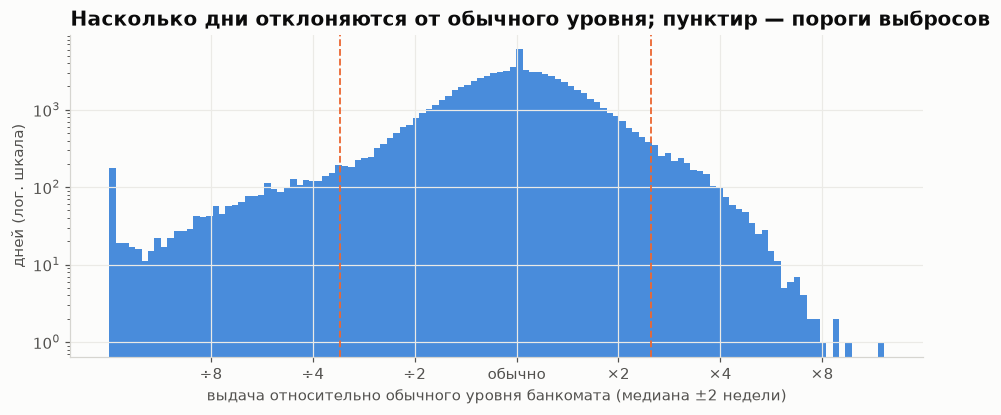

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.8))
r = np.log2(df.loc[ok, "ratio"].clip(1/16, 16))
ax.hist(r, bins=120, color=BLUE, alpha=0.85)
for x, c in [(np.log2(2.5), ORANGE), (np.log2(0.3), ORANGE)]:
    ax.axvline(x, color=c, linestyle="--", linewidth=1.2)
ax.set_yscale("log")
ax.set_xticks(np.log2([1/8, 1/4, 0.5, 1, 2, 4, 8]), ["÷8", "÷4", "÷2", "обычно", "×2", "×4", "×8"])
ax.set_xlabel("выдача относительно обычного уровня банкомата (медиана ±2 недели)")
ax.set_ylabel("дней (лог. шкала)")
ax.set_title("Насколько дни отклоняются от обычного уровня; пунктир — пороги выбросов")
save(fig, "11_outliers"); plt.show()

**Выводы и решения по выбросам:**
- Сильно необычных дней немного: **3,2%** с выдачей в 2,5+ раза выше обычной и **3,0%** — ниже 30% от обычной.
- **Высокие выбросы — это настоящий спрос, а не ошибки:** **92%** из них приходятся на особые дни (среди всех дней таких 33%). В основном это **пенсии и зарплата** (67% и 82% — флаги пересекаются, т.к. 10–14 число это и то, и другое) у банкоматов **Соцфонда и офисов**. Рекорд — ×12 у офисного ATM-0085 25.12.2024 (зарплата + конец года).
- **Низкие выбросы — тоже закономерность:** почти все — **офисные банкоматы в выходные**, когда офисы закрыты.
- Значит, удалять их нельзя: это ровно те пики, ради которых нужен прогноз (банкомат Соцфонда в день пенсий и пустеет). Если их выкинуть, модель будет занижать спрос в самые важные дни.
- **Решение:** выбросы **не удаляем**. Осталось проверить, не поможет ли мягкая обрезка самых экстремальных значений в train — это делаем на валидации в разделе 2.2.

## 2. Признаки

Берём ровно те же признаки, что в ноутбуке 02 (чтобы «LightGBM до» совпал с прошлым результатом), и добавляем два новых:

| Признак | Что это | Зачем |
|---|---|---|
| `dom` — день месяца | число 1–31 | зарплата (10–14 и 25–27) и пенсии (10–14) привязаны к датам, а не к дню недели. Флаги «зарплата/пенсия» говорят только «внутри окна или нет», а день месяца позволяет увидеть **форму** цикла: начало окна, пик, спад после. |
| `lag_28` — выдача 28 дней назад | без дней сбоев | 28 дней — это ровно 4 недели (тот же день недели) и почти месяц (почти та же фаза зарплатного цикла). Лаги 7 и 14 этого не дают. |

Разбиение и строки — те же, что в 02: train до 30.06.2025, test 01.07–31.12.2025, дни сбоев исключены (оцениваются отдельно).

In [7]:
g = df.groupby("atm_id", sort=False)
cg = clean_cash.groupby(df["atm_id"], sort=False)

for k in (1, 7, 14, 28):
    df[f"lag_{k}"] = cg.shift(k)
df["roll_mean_7"] = cg.transform(lambda s: s.shift(1).rolling(7, min_periods=3).mean())
df["roll_mean_28"] = cg.transform(lambda s: s.shift(1).rolling(28, min_periods=10).mean())
df["naive_lag7_raw"] = g["cash_out"].shift(7)
df["dow_mean_4w"] = pd.concat([cg.shift(k) for k in (7, 14, 21, 28)], axis=1).mean(axis=1)
for c in ["temp_avg", "precip_mm", "snowfall_mm", "wind_max"]:
    df[f"{c}_lag1"] = g[c].shift(1)
df["fx_shock_last3"] = g["fx_shock"].transform(
    lambda s: s.astype(int).shift(1).rolling(3, min_periods=1).max()).fillna(0).astype(int)
df["is_street"] = (df["placement"] == "street").astype(int)
df["dom"] = df.date.dt.day   # новый признак: день месяца

CAT = ["atm_type", "district_id"]
BOOL = ["is_holiday", "is_pre_holiday", "is_payday", "is_pension_day", "is_ramadan", "is_weekend", "is_street", "fx_shock_last3"]
NUM = ["lag_1", "lag_7", "lag_14", "roll_mean_7", "roll_mean_28",
       "temp_avg_lag1", "precip_mm_lag1", "snowfall_mm_lag1", "wind_max_lag1"]
FEATURES_OLD = ["dow"] + CAT + BOOL + NUM          # как в ноутбуке 02, в том же порядке
FEATURES_NEW = FEATURES_OLD + ["dom", "lag_28"]
for c in BOOL:
    df[c] = df[c].astype(int)
CATEGORIES = {c: sorted(df[c].unique()) for c in CAT}

has_history = df["naive_lag7_raw"].notna() & df["dow_mean_4w"].notna() & df["roll_mean_28"].notna()
train = df[(df.date <= TRAIN_END) & ~df.is_disrupted & has_history].copy()
test = df[(df.date >= TEST_START) & ~df.is_disrupted & has_history].copy()
test_disrupted = df[(df.date >= TEST_START) & df.is_disrupted & has_history].copy()
fit_part, val_part = train[train.date < VAL_START], train[train.date >= VAL_START]

print(f"train: {len(train):,}  (из них fit {len(fit_part):,} до 30.04.2025, валидация {len(val_part):,} май–июнь)")
print(f"test:  {len(test):,}   test, дни сбоев: {len(test_disrupted):,}")
print(f"Признаков: было {len(FEATURES_OLD)}, стало {len(FEATURES_NEW)}")
print(f"lag_28 пустой в train: {train.lag_28.isna().mean():.2%} (дни сбоев 28 дней назад или начало истории) — LightGBM это умеет")

train: 58,559  (из них fit 51,457 до 30.04.2025, валидация 7,102 май–июнь)
test:  21,726   test, дни сбоев: 301
Признаков: было 20, стало 22
lag_28 пустой в train: 4.80% (дни сбоев 28 дней назад или начало истории) — LightGBM это умеет


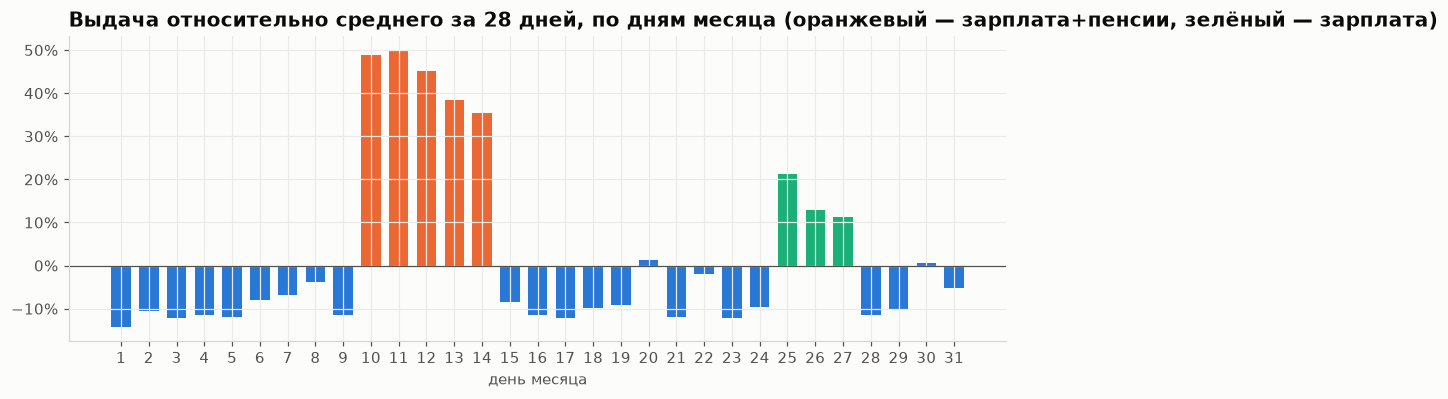

dom              1     2     3     4     5    6    7    8     9     10    11    12    13    14   15    16    17   18   19   20    21   22    23   24    25    26    27    28    29   30   31
отклонение, % -14.2 -10.6 -12.2 -11.6 -11.8 -7.9 -6.8 -3.9 -11.4  48.9  50.1  45.2  38.3  35.3 -8.4 -11.4 -12.3 -9.8 -9.2  1.3 -12.0 -2.0 -12.2 -9.6  21.3  12.8  11.2 -11.5 -10.0  0.7 -5.1

Корреляция выдачи с выдачей k дней назад (оба поделены на среднее за 28 дней):
   1 дн.: 0.246
   7 дн.: 0.257
  14 дн.: 0.364
  28 дн.: 0.449


In [8]:
# Почему день месяца: средняя выдача относительно обычного уровня по дням месяца (train, без сбоев)
tr = train.assign(rel=train.cash_out / train.roll_mean_28 - 1)
by_dom = tr.groupby("dom").rel.mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
colors = [ORANGE if (10 <= d <= 14) else AQUA if (25 <= d <= 27) else BLUE for d in by_dom.index]
ax.bar(by_dom.index, by_dom.values, color=colors, width=0.7)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_xticks(range(1, 32))
ax.set_xlabel("день месяца")
ax.set_title("Выдача относительно среднего за 28 дней, по дням месяца (оранжевый — зарплата+пенсии, зелёный — зарплата)")
save(fig, "12_day_of_month"); plt.show()
print((by_dom * 100).round(1).to_frame("отклонение, %").T.to_string())

# Насколько похожа выдача на выдачу k дней назад (корреляция отклонений от среднего, train)
rel = tr.cash_out / tr.roll_mean_28
print("\nКорреляция выдачи с выдачей k дней назад (оба поделены на среднее за 28 дней):")
for k in (1, 7, 14, 28):
    print(f"  {k:>2} дн.: {rel.corr(tr[f'lag_{k}'] / tr.roll_mean_28):.3f}")

**Что видно:**
- **День месяца — сильный сигнал:** 10–14 числа (зарплата + пенсии) выдача на **35–50% выше** среднего, 25–27 числа (зарплата) — на **11–21% выше**, в большинство остальных дней — на 4–14% ниже. Флаг «зарплата» один на оба окна, хотя по силе они отличаются в 2–3 раза; день месяца позволяет модели это различить.
- **Выдача 28 дней назад похожа на сегодняшнюю сильнее всего:** корреляция **0,45** против 0,36 у 14 дней, 0,26 у 7 дней и 0,25 у вчера. 28 дней назад — тот же день недели *и* почти то же число месяца, то есть та же фаза зарплатного цикла.
- **На валидации новые признаки снижают WAPE с 24,4% до 23,4%** (см. 2.1).

### 2.1 Как учим и оцениваем

- **Метрика подбора — WAPE на валидации** (май–июнь 2025). WAPE = сумма ошибок / сумма факта.
- **Число деревьев** везде подбирается одинаково: учим на данных до 30.04.2025, останавливаемся, когда ошибка на мае–июне 100 деревьев подряд не улучшается. Потом переобучаем на **всём train** с найденным числом деревьев.
- Параметры «до» — те же, что в ноутбуке 02.

In [9]:
BASE_PARAMS = dict(objective="regression", learning_rate=0.03, num_leaves=63, min_child_samples=40,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0)

def lgb_frame(d, feats):
    x = d[feats].copy()
    for c in CAT:
        if c in feats:
            x[c] = pd.Categorical(x[c], categories=CATEGORIES[c])
    return x

def wape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return np.abs(y - p).sum() / y.sum()

def mae(y, p):
    return np.mean(np.abs(np.asarray(y, float) - np.asarray(p, float)))

def probe(feats, params, y_fit=None, seed=SEED):
    """Учим на fit_part, early stopping по валидации. Возвращает (число деревьев, WAPE на валидации)."""
    m = lgb.LGBMRegressor(n_estimators=5000, random_state=seed, verbose=-1, **params)
    m.fit(lgb_frame(fit_part, feats), fit_part[TARGET] if y_fit is None else y_fit,
          eval_X=(lgb_frame(val_part, feats),), eval_y=(val_part[TARGET],), eval_metric="l1",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m.best_iteration_, wape(val_part[TARGET], m.predict(lgb_frame(val_part, feats), num_iteration=m.best_iteration_))

def final_fit(feats, params, n_trees, y_train=None, seed=SEED):
    m = lgb.LGBMRegressor(n_estimators=n_trees, random_state=seed, verbose=-1, **params)
    m.fit(lgb_frame(train, feats), train[TARGET] if y_train is None else y_train)
    return m

it_old, val_old = probe(FEATURES_OLD, BASE_PARAMS)
it_new, val_new = probe(FEATURES_NEW, BASE_PARAMS)
print(f"Валидация (май–июнь), параметры как в 02:")
print(f"  старые признаки: WAPE {val_old:.2%}  ({it_old} деревьев)")
print(f"  + dom, lag_28:   WAPE {val_new:.2%}  ({it_new} деревьев)")

Валидация (май–июнь), параметры как в 02:
  старые признаки: WAPE 24.39%  (359 деревьев)
  + dom, lag_28:   WAPE 23.40%  (303 деревьев)


### 2.2 Решение по выбросам: проверка на валидации

В разделе 1.3 высокие выбросы оказались в основном настоящим спросом. Но может ли модели всё равно помочь, если в **train** обрезать самые экстремальные значения (например, до 3 или 4 обычных уровней)? Проверяем на валидации. Валидацию и test **не обрезаем никогда**: в реальности такие дни будут, и честная оценка должна их включать.

In [10]:
clip_rows = []
for k in (None, 4.0, 3.0, 2.5):
    if k is None:
        y_fit = fit_part[TARGET]
    else:
        cap = fit_part.ref_med * k
        y_fit = np.where(fit_part.ref_med.notna(), np.minimum(fit_part[TARGET], cap), fit_part[TARGET])
    it, v = probe(FEATURES_NEW, BASE_PARAMS, y_fit=pd.Series(y_fit, index=fit_part.index))
    n_clipped = 0 if k is None else int((fit_part[TARGET] > fit_part.ref_med * k).sum())
    clip_rows.append({"обрезка train": "нет" if k is None else f"до {k:g}× обычного уровня",
                      "обрезано строк": n_clipped, "WAPE валидация": v, "деревьев": it})
clip_res = pd.DataFrame(clip_rows).set_index("обрезка train")
print(clip_res.to_string(formatters={"WAPE валидация": "{:.2%}".format}))

                         обрезано строк WAPE валидация  деревьев
обрезка train                                                   
нет                                   0         23.40%       303
до 4× обычного уровня               275         23.39%       303
до 3× обычного уровня               968         23.62%       285
до 2.5× обычного уровня            1690         23.89%       347


**Решение: выбросы в train не обрезаем.** Обрезка до 4 обычных уровней даёт 23,39% против 23,40% без обрезки — разница 0,01 п.п., это ничто. Обрезка сильнее (до 3× и 2,5×) **ухудшает** валидацию: модель перестаёт верить в пики пенсий и зарплат и занижает их. Это подтверждает вывод 1.3: экстремальные дни — полезная информация, а не мусор.

## 3. Подбор параметров с Optuna

**Что подбираем** (в скобках — названия в sklearn-интерфейсе LightGBM):

| Параметр | Смысл | Диапазон |
|---|---|---|
| `num_leaves` | сколько листьев в дереве — насколько сложные сочетания признаков модель может выучить | 15–255 |
| `learning_rate` | насколько сильно каждое новое дерево исправляет ошибки предыдущих | 0,01–0,2 |
| `min_child_samples` | минимум строк в листе — защита от подгонки под единичные дни | 5–300 |
| `feature_fraction` (`colsample_bytree`) | какую долю признаков видит каждое дерево | 0,3–1,0 |
| `lambda_l2` (`reg_lambda`) | штраф за слишком большие значения в листьях | 0,001–100 |

- **45 попыток** (trials), алгоритм TPE: каждая следующая попытка выбирается с учётом предыдущих.
- **Первая попытка — параметры из ноутбука 02**, поэтому результат Optuna на валидации точно не хуже старого.
- В каждой попытке число деревьев подбирается early stopping по валидации.
- Признаки — новые (`FEATURES_NEW`). Test в подборе не участвует.

In [11]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 45
Xf, Xv = lgb_frame(fit_part, FEATURES_NEW), lgb_frame(val_part, FEATURES_NEW)

def to_lgb(p):
    """Параметры trial -> параметры LGBMRegressor."""
    return dict(objective="regression", subsample=0.8, subsample_freq=1,
                num_leaves=p["num_leaves"], learning_rate=p["learning_rate"],
                min_child_samples=p["min_child_samples"], colsample_bytree=p["feature_fraction"],
                reg_lambda=p["lambda_l2"])

def objective(trial):
    p = {
        "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 300, log=True),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.3, 1.0),
        "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 100, log=True),
    }
    m = lgb.LGBMRegressor(n_estimators=5000, random_state=SEED, verbose=-1, **to_lgb(p))
    m.fit(Xf, fit_part[TARGET], eval_X=(Xv,), eval_y=(val_part[TARGET],), eval_metric="l1",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    trial.set_user_attr("n_trees", m.best_iteration_)
    return wape(val_part[TARGET], m.predict(Xv, num_iteration=m.best_iteration_))

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial({"num_leaves": 63, "learning_rate": 0.03, "min_child_samples": 40,
                     "feature_fraction": 0.8, "lambda_l2": 1.0})   # старт: параметры из 02
study.optimize(objective, n_trials=N_TRIALS)

best = study.best_trial
TUNED_PARAMS = to_lgb(best.params)
N_TREES_TUNED = best.user_attrs["n_trees"]
print(f"Лучшая попытка #{best.number}: WAPE на валидации {best.value:.2%} "
      f"(старт с параметрами из 02: {study.trials[0].value:.2%})")
print("Параметры:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best.params.items()},
      "| деревьев:", N_TREES_TUNED)

trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in trials.columns]
print("\nТоп-5 попыток:")
print(trials.sort_values("value").head(5).round(4).to_string(index=False))

Лучшая попытка #40: WAPE на валидации 23.18% (старт с параметрами из 02: 23.40%)
Параметры: {'num_leaves': 76, 'learning_rate': 0.0124, 'min_child_samples': 8, 'feature_fraction': 0.669, 'lambda_l2': 0.0018} | деревьев: 897

Топ-5 попыток:
 number  value  feature_fraction  lambda_l2  learning_rate  min_child_samples  num_leaves  n_trees
     40 0.2318            0.6690     0.0018         0.0124                  8          76      897
     42 0.2321            0.6628     0.0011         0.0121                  6          68      928
      5 0.2322            0.5565     0.1907         0.0152                 15          84      661
     41 0.2323            0.6540     0.0269         0.0137                  7          84      749
     21 0.2324            0.6570     0.0035         0.0125                 11          84      906


Важность параметров: {'learning_rate': 45.0, 'min_child_samples': 22.0, 'feature_fraction': 15.0, 'num_leaves': 12.0, 'lambda_l2': 7.0}


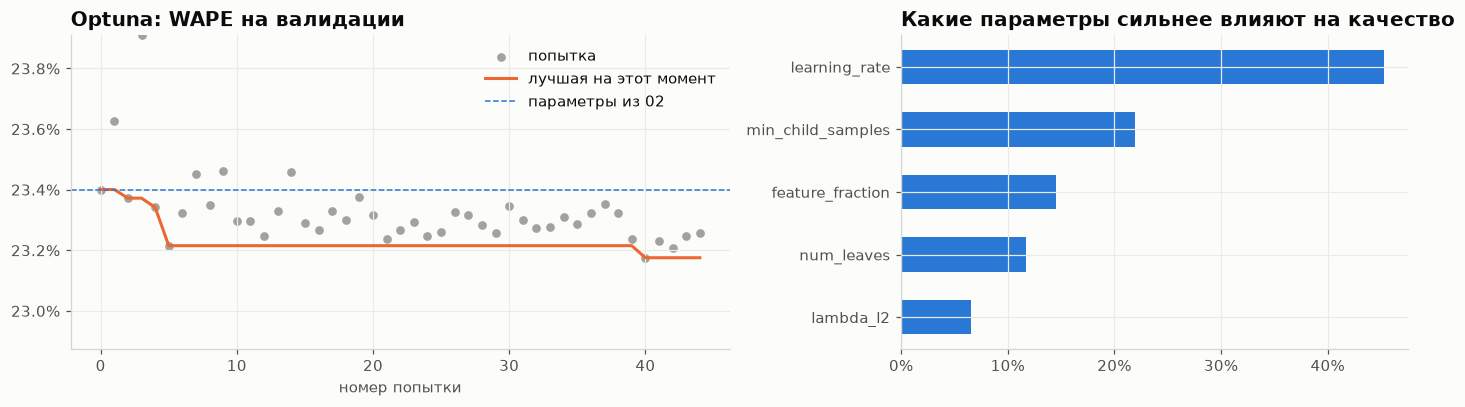

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.scatter(trials.number, trials.value, color=GRAY, s=22, label="попытка")
ax.plot(trials.number, trials.value.cummin(), color=ORANGE, label="лучшая на этот момент")
ax.axhline(study.trials[0].value, color=BLUE, linestyle="--", linewidth=1, label="параметры из 02")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=1))
ax.set_ylim(trials.value.min() - 0.003, min(trials.value.max(), trials.value.min() + 0.03))
ax.set_xlabel("номер попытки"); ax.set_title("Optuna: WAPE на валидации")
ax.legend(loc="upper right")

ax = axes[1]
try:
    imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
    ax.barh(imp.index, imp.values, color=BLUE, height=0.55)
    ax.xaxis.set_major_formatter(pct0)
    ax.set_title("Какие параметры сильнее влияют на качество")
    print("Важность параметров:", (imp.sort_values(ascending=False) * 100).round(0).to_dict())
except Exception as e:  # оценка важности может не поддерживаться в некоторых версиях
    ax.set_visible(False); print("Важность параметров не посчитана:", e)
fig.tight_layout(); save(fig, "13_optuna"); plt.show()

**Что видно:**
- Лучшая попытка: **WAPE 23,18% на валидации** против 23,40% у параметров из 02 — улучшение **всего 0,2 п.п.**
- Optuna выбрала **медленное обучение** (`learning_rate` 0,012 вместо 0,03 → 897 деревьев вместо 303), **больше листьев** (76 вместо 63), **меньше строк в листе** (8 вместо 40), меньшую долю признаков на дерево (0,67) и почти без L2-штрафа.
- **Сильнее всего на качество влияет `learning_rate` (45%)**, затем `min_child_samples` (22%); `lambda_l2` почти не важен (7%).
- Топ-5 попыток очень похожи друг на друга и отличаются на 0,06 п.п. — **плато**: ближе к этому месту качество почти не меняется, дальше искать бессмысленно.
- **Простыми словами:** параметры из 02 уже были близки к оптимальным. Optuna нашла немного лучше, но главный выигрыш на валидации дали новые признаки (−1,0 п.п.), а не подбор (−0,2 п.п.).
- Осторожно: 45 попыток на одних и тех же 2 месяцах — часть выигрыша может быть «подгонкой под валидацию». Поэтому честный ответ даст только test.

## 4. Результат на test (июль–декабрь 2025)

Только здесь впервые смотрим на test. Чтобы разделить вклад признаков и Optuna, обучаем **четыре варианта** LightGBM — все сочетания «старые/новые признаки» × «параметры из 02 / параметры Optuna»:

| | параметры из 02 | параметры Optuna |
|---|---|---|
| **старые признаки** | A. LightGBM до | C. только Optuna |
| **+ dom, lag_28** | B. только признаки | D. LightGBM после |

Для каждого варианта число деревьев подобрано по валидации, затем модель переобучена на всём train (до 30.06.2025).

In [13]:
it_c, val_c = probe(FEATURES_OLD, TUNED_PARAMS)
variants = {
    "A. LightGBM до (как в 02)":        (FEATURES_OLD, BASE_PARAMS, it_old, val_old),
    "B. + новые признаки":              (FEATURES_NEW, BASE_PARAMS, it_new, val_new),
    "C. + Optuna (старые признаки)":    (FEATURES_OLD, TUNED_PARAMS, it_c, val_c),
    "D. LightGBM после (признаки + Optuna)": (FEATURES_NEW, TUNED_PARAMS, N_TREES_TUNED, best.value),
}
models, preds, preds_dis, rows = {}, {}, {}, []
y, y_dis = test[TARGET], test_disrupted[TARGET]

for name, base_col in [("Naive (7 дней назад)", "naive_lag7_raw"), ("Среднее по дню недели (4 нед.)", "dow_mean_4w")]:
    preds[name], preds_dis[name] = test[base_col].values, test_disrupted[base_col].values
    rows.append({"модель": name, "WAPE валидация": wape(val_part[TARGET], val_part[base_col]), "деревьев": np.nan})

for name, (feats, params, n_trees, v) in variants.items():
    m = final_fit(feats, params, n_trees)
    models[name] = m
    preds[name] = m.predict(lgb_frame(test, feats))
    preds_dis[name] = m.predict(lgb_frame(test_disrupted, feats))
    rows.append({"модель": name, "WAPE валидация": v, "деревьев": n_trees})

res = pd.DataFrame(rows).set_index("модель")
res["MAE test, сом"] = [mae(y, preds[n]) for n in res.index]
res["WAPE test"] = [wape(y, preds[n]) for n in res.index]
res["WAPE test, дни сбоев"] = [wape(y_dis, preds_dis[n]) for n in res.index]

fmt = {"MAE test, сом": fmt_int, "WAPE test": "{:.2%}".format, "WAPE валидация": "{:.2%}".format,
       "WAPE test, дни сбоев": "{:.2%}".format, "деревьев": lambda v: "" if pd.isna(v) else f"{v:.0f}"}
print("Test: 01.07–31.12.2025, обычные дни (без сбоев)")
print(res.to_string(formatters=fmt))
print(f"\nСредняя выдача в test: {fmt_int(y.mean())} сом")

Test: 01.07–31.12.2025, обычные дни (без сбоев)
                                      WAPE валидация деревьев MAE test, сом WAPE test WAPE test, дни сбоев
модель                                                                                                    
Naive (7 дней назад)                          40.65%      NaN       218 028    38.25%               44.59%
Среднее по дню недели (4 нед.)                30.46%      NaN       168 136    29.50%               36.50%
A. LightGBM до (как в 02)                     24.39%      359       133 229    23.37%               26.27%
B. + новые признаки                           23.40%      303       130 008    22.81%               25.49%
C. + Optuna (старые признаки)                 24.29%      963       133 052    23.34%               25.98%
D. LightGBM после (признаки + Optuna)         23.18%      897       129 515    22.72%               25.24%

Средняя выдача в test: 570 036 сом


In [14]:
A, B, Cc, D = list(variants)
w = res["WAPE test"]; m_ = res["MAE test, сом"]
eff = pd.DataFrame({
    "что меняем": ["новые признаки (A → B)", "Optuna (B → D)", "всё вместе (A → D)",
                   "для проверки: Optuna без новых признаков (A → C)", "для проверки: признаки при параметрах Optuna (C → D)"],
    "WAPE, п.п.": [w[B] - w[A], w[D] - w[B], w[D] - w[A], w[Cc] - w[A], w[D] - w[Cc]],
    "MAE, сом": [m_[B] - m_[A], m_[D] - m_[B], m_[D] - m_[A], m_[Cc] - m_[A], m_[D] - m_[Cc]],
})
eff["WAPE, п.п."] = (eff["WAPE, п.п."] * 100).round(2)
eff["MAE, сом"] = eff["MAE, сом"].round(0)
print("Вклад изменений на test (минус = ошибка уменьшилась):")
print(eff.to_string(index=False))

# Устойчивость: не случайность ли разница? Переобучаем A и D с 5 разными seed.
seed_rows = {}
for name in (A, D):
    feats, params, n_trees, _ = variants[name]
    seed_rows[name] = [wape(y, final_fit(feats, params, n_trees, seed=s).predict(lgb_frame(test, feats)))
                       for s in (1, 2, 3, 4, 5)]
seeds = pd.DataFrame(seed_rows)
print("\nWAPE на test при 5 разных seed (случайность в подвыборках строк и признаков):")
print(seeds.agg(["mean", "std", "min", "max"]).T.map(lambda v: f"{v:.2%}").to_string())
print(f"Разница D − A при разных seed: {((seeds[D] - seeds[A]) * 100).round(2).tolist()} п.п.")

Вклад изменений на test (минус = ошибка уменьшилась):
                                          что меняем  WAPE, п.п.  MAE, сом
                              новые признаки (A → B)       -0.56   -3220.0
                                      Optuna (B → D)       -0.09    -493.0
                                  всё вместе (A → D)       -0.65   -3714.0
    для проверки: Optuna без новых признаков (A → C)       -0.03    -177.0
для проверки: признаки при параметрах Optuna (C → D)       -0.62   -3537.0



WAPE на test при 5 разных seed (случайность в подвыборках строк и признаков):
                                         mean    std     min     max
A. LightGBM до (как в 02)              23.34%  0.02%  23.32%  23.38%
D. LightGBM после (признаки + Optuna)  22.75%  0.01%  22.74%  22.76%
Разница D − A при разных seed: [-0.56, -0.58, -0.6, -0.58, -0.62] п.п.


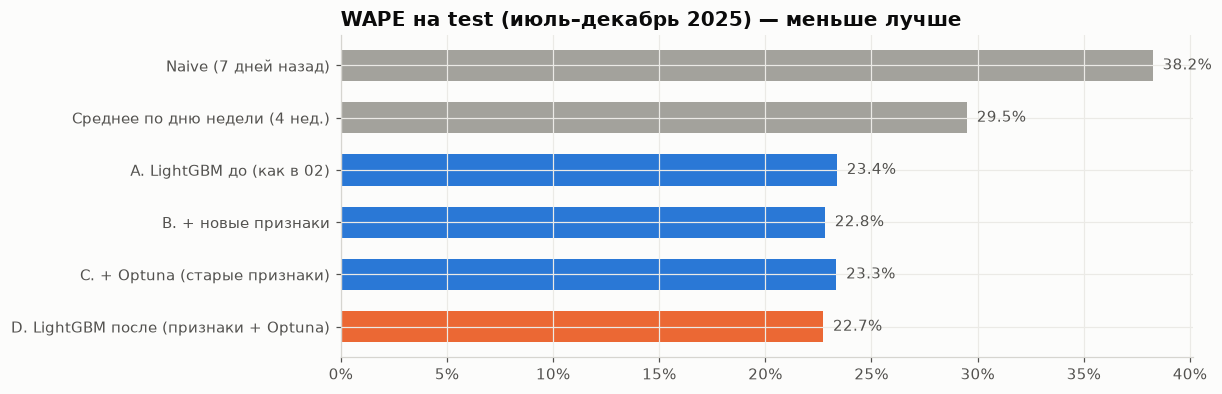

In [15]:
order = res.index[::-1]
fig, ax = plt.subplots(figsize=(10, 3.8))
colors = [ORANGE if n.startswith("D") else BLUE if n[:2] in ("A.", "B.", "C.") else GRAY for n in order]
ax.barh(order, res.loc[order, "WAPE test"], color=colors, height=0.6)
for yv, v in enumerate(res.loc[order, "WAPE test"]):
    ax.text(v, yv, f"  {v:.1%}", va="center", fontsize=10, color=INK2)
ax.xaxis.set_major_formatter(pct0)
ax.set_title("WAPE на test (июль–декабрь 2025) — меньше лучше")
save(fig, "14_wape_before_after"); plt.show()

**Что видно:**
- **Итог: WAPE 23,37% → 22,72%** (−0,65 п.п.), MAE **133 229 → 129 515 сом** (−3,7 тыс. сом в день на банкомат). «LightGBM до» совпал с ноутбуком 02 — значит, сравнение честное.
- **Почти весь выигрыш дали новые признаки: −0,56 п.п.** (A → B). Optuna добавила лишь **−0,09 п.п.** (B → D). Без новых признаков Optuna не даёт почти ничего (A → C: −0,03 п.п.), а признаки работают при любых параметрах (C → D: −0,62 п.п.). Вывод: модели не хватало **информации о цикле зарплат**, а не «настройки».
- **Это не случайность:** при 5 разных seed разница D − A стабильно от −0,56 до −0,62 п.п., а разброс одной модели — 0,01–0,02 п.п.
- **На днях сбоев** тоже лучше: 26,3% → 25,2%.
- **Валидация предсказала test правильно** по порядку моделей: B лучше A, D немного лучше B.
- **Цена Optuna:** модель D в 3 раза больше по числу деревьев (897 против 303) и медленнее учится. Ради 0,09 п.п. это оправдано только потому, что модель всё равно маленькая (2,3 МБ) и учится за секунды. Если важна простота, вариант B почти так же хорош.
- Относительно лучшей простой модели (среднее по дню недели, 29,5%) LightGBM теперь точнее на **23%** (было 21%).

## 5. Где модель ошибается сильнее всего

Разбираем ошибки лучшей модели (D) на test. Для каждой группы смотрим:
- **WAPE** — относительная ошибка внутри группы;
- **смещение** — систематически завышаем (+) или занижаем (−);
- **доля всей ошибки** — какой кусок общей суммы ошибок приходится на группу (важно для бизнеса: маленькая группа с большим WAPE может почти не влиять на итог);
- **WAPE «до»** — для сравнения с моделью A.

In [16]:
BEST = D
t = test.assign(pred=preds[BEST], pred_before=preds[A])
t["abs_err"] = (t[TARGET] - t.pred).abs()
dow_names = {1: "Пн", 2: "Вт", 3: "Ср", 4: "Чт", 5: "Пт", 6: "Сб", 7: "Вс"}
month_names = {7: "июль", 8: "август", 9: "сентябрь", 10: "октябрь", 11: "ноябрь", 12: "декабрь"}
t["день недели"] = t.dow.map(dow_names)
t["месяц"] = t.date.dt.month.map(month_names)
t["тип дня"] = np.select(
    [t.is_holiday == 1, t.is_pre_holiday == 1, t.is_pension_day == 1, t.is_payday == 1, t.is_weekend == 1],
    ["праздник", "предпраздник", "пенсии + зарплата (10–14)", "зарплата (25–27)", "обычный выходной"],
    "обычный будний")
total_err = t.abs_err.sum()

def err_by(col, order=None):
    r = t.groupby(col).apply(lambda p: pd.Series({
        "строк": len(p),
        "ср. выдача, тыс.": p[TARGET].mean() / 1e3,
        "WAPE": wape(p[TARGET], p.pred),
        "WAPE до": wape(p[TARGET], p.pred_before),
        "смещение": (p.pred - p[TARGET]).sum() / p[TARGET].sum(),
        "доля всей ошибки": p.abs_err.sum() / total_err,
    }), include_groups=False)
    return r.reindex(order) if order else r.sort_values("WAPE", ascending=False)

ef = {"строк": "{:.0f}".format, "ср. выдача, тыс.": "{:.0f}".format, "WAPE": "{:.1%}".format,
      "WAPE до": "{:.1%}".format, "смещение": "{:+.1%}".format, "доля всей ошибки": "{:.1%}".format}
e_type = err_by("atm_type")
e_dow = err_by("день недели", list(dow_names.values()))
e_month = err_by("месяц", list(month_names.values()))
e_day = err_by("тип дня")
for title, e in [("По типу банкомата", e_type), ("По дню недели", e_dow), ("По месяцу", e_month), ("По типу дня", e_day)]:
    print(f"{title}:"); print(e.to_string(formatters=ef)); print()

По типу банкомата:
                 строк ср. выдача, тыс.  WAPE WAPE до смещение доля всей ошибки
atm_type                                                                       
office_business   3158              596 24.0%   24.8%    -0.2%            16.0%
pension_social    2908              416 23.7%   24.6%    +1.5%            10.2%
highway_gas       2554              335 23.4%   24.3%    -0.0%             7.1%
tourist_center    1828              536 23.4%   23.7%    +5.5%             8.2%
residential       4747              428 23.1%   23.8%    -0.1%            16.7%
shopping_mall     2541              742 22.3%   22.7%    +0.1%            14.9%
transport_market  3990              887 21.3%   22.0%    +0.1%            26.8%

По дню недели:
            строк ср. выдача, тыс.  WAPE WAPE до смещение доля всей ошибки
день недели                                                               
Пн           3079              555 22.8%   23.5%    +0.8%            13.8%
Вт           3191   

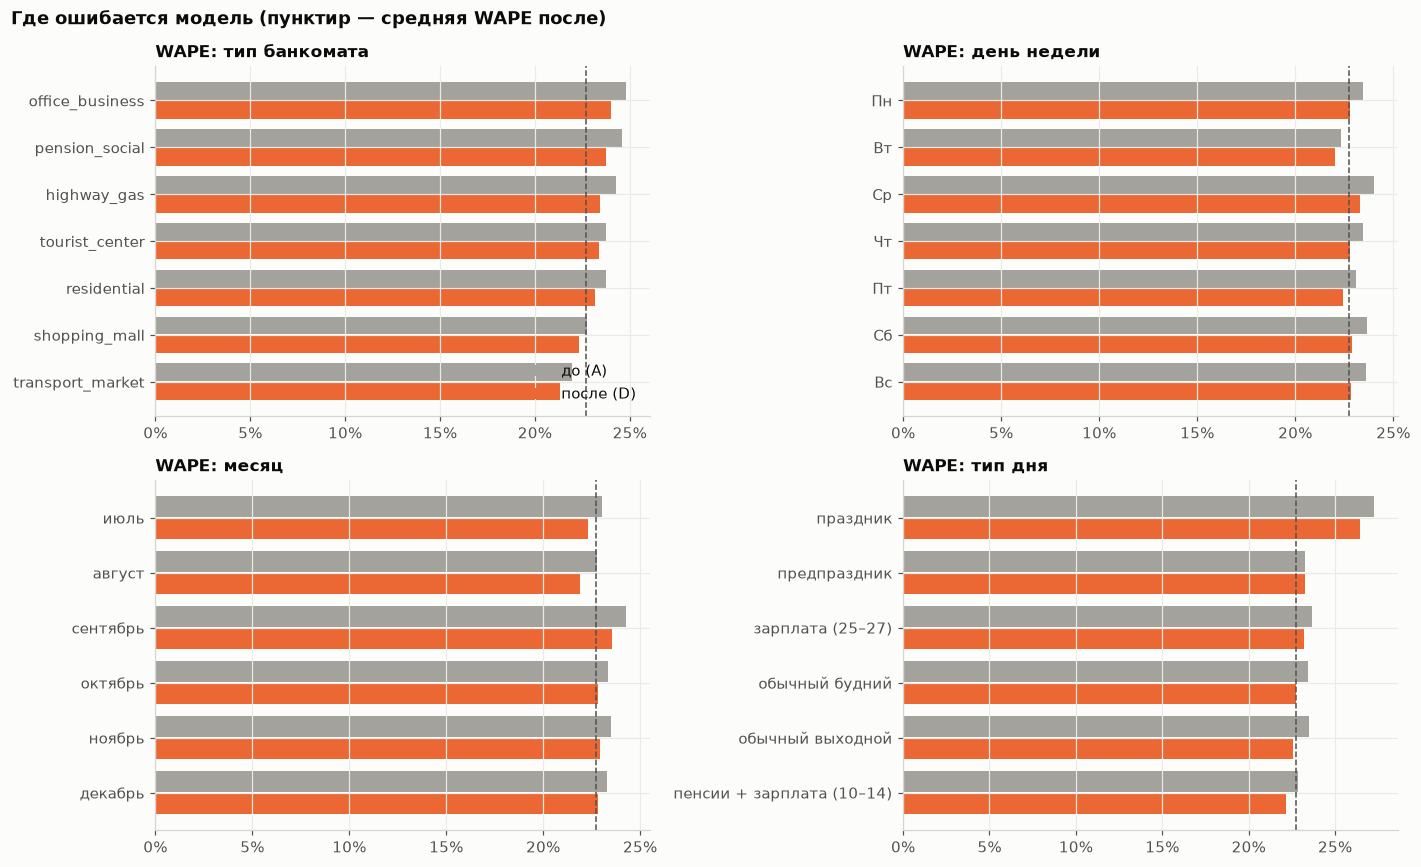

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (title, e) in zip(axes.flat, [("Тип банкомата", e_type), ("День недели", e_dow),
                                       ("Месяц", e_month), ("Тип дня", e_day)]):
    idx = list(e.index)[::-1]
    yy = np.arange(len(idx))
    ax.barh(yy + 0.2, e.loc[idx, "WAPE до"], height=0.38, color=GRAY, label="до (A)")
    ax.barh(yy - 0.2, e.loc[idx, "WAPE"], height=0.38, color=ORANGE, label="после (D)")
    ax.set_yticks(yy, idx)
    ax.axvline(wape(t[TARGET], t.pred), color=INK2, linestyle="--", linewidth=1)
    ax.xaxis.set_major_formatter(pct0)
    ax.set_title(f"WAPE: {title.lower()}", fontsize=11)
axes[0, 0].legend(loc="lower right")
fig.suptitle("Где ошибается модель (пунктир — средняя WAPE после)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "15_errors_by_group"); plt.show()

### 5.1 Почему одни банкоматы предсказываются хуже других

Гипотеза: ошибка зависит не столько от модели, сколько от **шумности** самого банкомата. Если у банкомата в день 40 операций, один клиент с крупной суммой сильно сдвигает итог; если 300 — случайности усредняются. Проверяем для каждого банкомата:
- **операций выдачи в день** (в train);
- **шумность** — средний разброс дневной выдачи вокруг своего среднего за 28 дней в train (|выдача / среднее − 1|), то есть насколько банкомат «скачет» сам по себе;
- **средний чек** — сумма выдачи / число операций.

In [18]:
tr = train.assign(noise=(train[TARGET] / train.roll_mean_28 - 1).abs(),
                  ticket=train[TARGET] / train.n_cash_txn.replace(0, np.nan))
atm_stats = tr.groupby("atm_id").agg(txn_per_day=("n_cash_txn", "mean"),
                                     noise=("noise", "mean"), ticket=("ticket", "mean"))
atm_err = t.groupby("atm_id").apply(lambda p: pd.Series({
    "WAPE": wape(p[TARGET], p.pred), "смещение": (p.pred - p[TARGET]).sum() / p[TARGET].sum(),
    "выдача, тыс./день": p[TARGET].mean() / 1e3, "дней": len(p)}), include_groups=False)
atm = atm_err.join(atm_stats)
atm["atm_type"] = t.groupby("atm_id").atm_type.first()   # из test: у новых банкоматов может не быть train
print("Банкоматов в test без истории в train:", atm.txn_per_day.isna().sum())
atm["new_atm"] = atm.index.isin(cold.index)

print("Связь ошибки банкомата с его свойствами (корреляция Спирмена с WAPE на test):")
for c, label in [("noise", "шумность в train"), ("txn_per_day", "операций в день"),
                 ("ticket", "средний чек"), ("выдача, тыс./день", "объём выдачи")]:
    print(f"  {label:<18} {atm['WAPE'].corr(atm[c], method='spearman'):+.2f}")

print("\n10 банкоматов с самой большой ошибкой:")
print(atm.sort_values("WAPE", ascending=False).head(10)[
    ["atm_type", "WAPE", "смещение", "выдача, тыс./день", "txn_per_day", "noise", "ticket", "new_atm"]
].to_string(formatters={"WAPE": "{:.1%}".format, "смещение": "{:+.1%}".format, "выдача, тыс./день": "{:.0f}".format,
                         "txn_per_day": "{:.0f}".format, "noise": "{:.0%}".format, "ticket": "{:.0f}".format}))
print("\n10 банкоматов с самой маленькой ошибкой:")
print(atm.sort_values("WAPE").head(10)[["atm_type", "WAPE", "выдача, тыс./день", "txn_per_day", "noise"]].to_string(
    formatters={"WAPE": "{:.1%}".format, "выдача, тыс./день": "{:.0f}".format, "txn_per_day": "{:.0f}".format, "noise": "{:.0%}".format}))

if atm.new_atm.any():
    print("\nНовые банкоматы (установлены внутри периода) против старых, WAPE:")
    print(t.assign(new_atm=t.atm_id.isin(cold.index)).groupby("new_atm").apply(
        lambda p: f"{wape(p[TARGET], p.pred):.1%} ({p.atm_id.nunique()} банкоматов)", include_groups=False).to_string())

Банкоматов в test без истории в train: 1
Связь ошибки банкомата с его свойствами (корреляция Спирмена с WAPE на test):
  шумность в train   +0.25
  операций в день    -0.53
  средний чек        -0.10
  объём выдачи       -0.49

10 банкоматов с самой большой ошибкой:
                  atm_type  WAPE смещение выдача, тыс./день txn_per_day noise ticket  new_atm
atm_id                                                                                       
ATM-0011    pension_social 30.8%    +8.7%               194          44   56%   3751    False
ATM-0069   office_business 28.2%    +9.0%               327          68   64%   4230    False
ATM-0039   office_business 27.9%    +7.4%               413          84   61%   4297    False
ATM-0120    pension_social 26.5%    -0.2%               464         103   57%   3762    False
ATM-0037       highway_gas 26.4%    +3.2%               200          44   29%   4192    False
ATM-0042       residential 26.3%    +1.9%               344          74   2

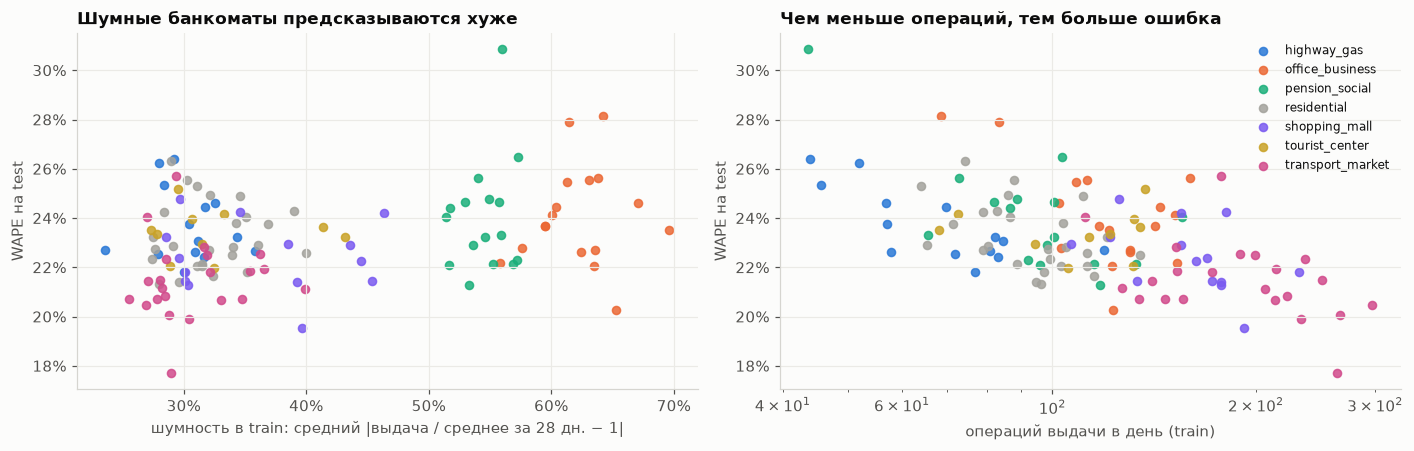

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
types = sorted(atm.atm_type.unique())
palette = dict(zip(types, [BLUE, ORANGE, AQUA, GRAY, "#7a5af0", "#c9a227", "#d14a8b"]))
for ax, (col, label) in zip(axes, [("noise", "шумность в train: средний |выдача / среднее за 28 дн. − 1|"),
                                   ("txn_per_day", "операций выдачи в день (train)")]):
    for tp in types:
        s = atm[atm.atm_type == tp]
        ax.scatter(s[col], s.WAPE, s=28, color=palette[tp], label=tp, alpha=0.85)
    ax.set_xlabel(label); ax.set_ylabel("WAPE на test")
    ax.yaxis.set_major_formatter(pct0)
    if col == "noise":
        ax.xaxis.set_major_formatter(pct0)
    else:
        ax.set_xscale("log")
axes[0].set_title("Шумные банкоматы предсказываются хуже", fontsize=11)
axes[1].set_title("Чем меньше операций, тем больше ошибка", fontsize=11)
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout(); save(fig, "16_atm_noise_vs_error"); plt.show()

In [20]:
# Смещение по месяцам: растёт ли спрос быстрее, чем видит модель (дрейф второго года)
monthly = t.groupby(t.date.dt.to_period("M")).apply(lambda p: pd.Series({
    "факт, млн": p[TARGET].sum() / 1e6, "прогноз, млн": p.pred.sum() / 1e6,
    "смещение": (p.pred - p[TARGET]).sum() / p[TARGET].sum()}), include_groups=False)
print(monthly.to_string(formatters={"факт, млн": "{:.0f}".format, "прогноз, млн": "{:.0f}".format, "смещение": "{:+.1%}".format}))

# Сколько примеров особых дней было в train
print("\nОсобых дней в train (уникальных дат):")
for col, label in [("is_holiday", "праздник"), ("is_pre_holiday", "предпраздник"),
                   ("is_pension_day", "пенсии"), ("is_payday", "зарплата")]:
    print(f"  {label:<13} {train.loc[train[col] == 1, 'date'].nunique():>3}")
print("\nПраздники в test:", sorted(t.loc[t.is_holiday == 1, "holiday_name"].dropna().unique()))
hol = t[(t.is_holiday == 1) | (t.is_pre_holiday == 1)].groupby(["date", "holiday_name"], dropna=False).apply(
    lambda p: pd.Series({"WAPE": wape(p[TARGET], p.pred), "смещение": (p.pred - p[TARGET]).sum() / p[TARGET].sum()}),
    include_groups=False)
print(hol.to_string(formatters={"WAPE": "{:.1%}".format, "смещение": "{:+.1%}".format}))

        факт, млн прогноз, млн смещение
date                                   
2025-07      2182         2169    -0.6%
2025-08      2191         2177    -0.6%
2025-09      2036         2074    +1.9%
2025-10      2025         2056    +1.6%
2025-11      1978         1984    +0.3%
2025-12      1973         1995    +1.1%

Особых дней в train (уникальных дат):
  праздник       28
  предпраздник   13
  пенсии         89
  зарплата      143

Праздники в test: ['День независимости', 'Дни истории и памяти предков']
                                         WAPE смещение
date       holiday_name                               
2025-08-30 NaN                          21.9%    -6.5%
2025-08-31 День независимости           24.1%    -1.3%
2025-11-06 NaN                          22.8%    -3.3%
2025-11-07 Дни истории и памяти предков 28.9%   +11.6%
2025-11-08 Дни истории и памяти предков 26.7%    +9.4%
2025-12-31 NaN                          25.4%    +1.7%


**Где модель ошибается и почему:**

1. **Сильнее всего — праздники (WAPE 26,4%) и переоценка в них (+6,2%).** В test два праздника: 31 августа (всё нормально, 24%) и **7–8 ноября** — там модель **переоценила спрос на 9–12%**. Причина: в train всего **28 праздничных дат**, и праздники ведут себя по-разному (одни дают пик покупок, другие — тишину), а модель видит только общий флаг «праздник». Вклад в общую ошибку небольшой — **1,5%**, потому что праздников мало.
2. **Типы банкоматов: офисы (24,0%) и Соцфонд (23,7%) хуже всех, рынки (21,3%) лучше всех.** У офисов и Соцфонда самые резкие скачки (выходные почти до нуля, пенсии ×3–4), и в них **меньше операций** в день. Но больше всего денег в ошибке — у **рынков (27% всей ошибки)**: WAPE у них низкий, зато суммы самые большие.
3. **Главная причина различий между банкоматами — число операций.** Корреляция WAPE с числом операций выдачи в день **−0,53**: у банкомата с 44 операциями в день (ATM-0011, Соцфонд) ошибка 31%, у банкоматов рынков с 250+ операциями — 18–20%. Чем меньше клиентов, тем сильнее итог дня зависит от случайности — пара крупных снятий сдвигает сумму на десятки процентов. Это **случайный шум, его нельзя убрать улучшением модели**; можно только учитывать при планировании (держать больший запас на тихих банкоматах).
4. **Дни недели — почти без разницы** (22,0–23,3%). Выходные чуть переоценены (+1,6%), но несильно — модель хорошо знает недельный ритм.
5. **Месяцы — тоже ровно** (21,9–23,6%). Небольшая **переоценка с сентября (+1–2%)**: летом выдача была выше, осенью сеть немного просела, а модель обучена на данных до июня и «помнит» летний уровень. Скользящие средние частично это ловят, но с запаздыванием. Это аргумент **регулярно переобучать** модель (например, раз в месяц).
6. **Предпраздничные дни** (23,3%) — модель немного **занижает** (−2,9%): 30 августа и 6 ноября спрос был выше, чем она ожидала. Предпраздников в train всего 13.
7. **Новые банкоматы не хуже старых** (22,7% и 22,7%). ATM-0024 установлен уже в test (13.08.2025) и не имел ни одного дня в train, но его ошибка 26% — на уровне других офисных банкоматов. Модель переносит знания о типе точки на новый банкомат.
8. **Новые признаки улучшили все группы без исключения** — нет ни одного типа, дня или месяца, где стало хуже.

## 6. Сохранение модели

Сохраняем модель D (лучшую) в `models/`:
- `lgbm_cash_forecast.joblib` — сама модель (обучена на данных до 30.06.2025);
- `features.json` — список признаков в нужном порядке, категории, параметры, период обучения и метрики.

Модель обучена на train (до 30.06.2025) — ровно та, чьи метрики в таблице выше. Для боевого прогноза её стоит переобучить на всех данных по 31.12.2025 с теми же параметрами и числом деревьев.

In [21]:
MODELS.mkdir(exist_ok=True)
final_model = models[BEST]
model_path, meta_path = MODELS / "lgbm_cash_forecast.joblib", MODELS / "features.json"
joblib.dump(final_model, model_path, compress=3)

meta = {
    "model": "LightGBM (LGBMRegressor), признаки из notebooks/03_optimization.ipynb",
    "target": "cash_out — выдача наличных банкоматом за день, сом",
    "forecast": "прогноз на день D, сделанный вечером дня D−1",
    "features": FEATURES_NEW,
    "categorical": {c: [str(v) for v in CATEGORIES[c]] for c in CAT},
    "feature_notes": {
        "lag_k": "выдача k дней назад; дни сбоев (is_disrupted) заменены на пропуск",
        "roll_mean_7 / roll_mean_28": "среднее за 7 / 28 дней по D−1 включительно, без дней сбоев",
        "*_lag1": "погода вчера (D−1)",
        "fx_shock_last3": "был ли скачок курса за D−3…D−1",
        "dom": "день месяца",
        "dow": "день недели, 1 = Пн … 7 = Вс",
    },
    "params": {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in TUNED_PARAMS.items()},
    "n_estimators": int(N_TREES_TUNED),
    "random_state": SEED,
    "train_period": [str(train.date.min().date()), str(train.date.max().date())],
    "validation_period": [str(VAL_START.date()), str(TRAIN_END.date())],
    "test_period": [str(test.date.min().date()), str(test.date.max().date())],
    "metrics_test": {"MAE": round(float(res.loc[BEST, "MAE test, сом"]), 0),
                     "WAPE": round(float(res.loc[BEST, "WAPE test"]), 4),
                     "WAPE_disrupted_days": round(float(res.loc[BEST, "WAPE test, дни сбоев"]), 4)},
    "metrics_validation": {"WAPE": round(float(best.value), 4)},
    "versions": {"python": platform.python_version(), "lightgbm": lgb.__version__,
                 "scikit-learn": sklearn.__version__, "pandas": pd.__version__},
}
meta_path.write_text(json.dumps(meta, ensure_ascii=False, indent=2))

# Проверка: загруженная модель даёт тот же прогноз
loaded = joblib.load(model_path)
same = np.allclose(loaded.predict(lgb_frame(test, json.loads(meta_path.read_text())["features"])), preds[BEST])
print(f"{model_path.relative_to(ROOT)}: {model_path.stat().st_size / 1024:,.0f} КБ")
print(f"{meta_path.relative_to(ROOT)}: {meta_path.stat().st_size / 1024:,.1f} КБ")
print("Загруженная модель даёт тот же прогноз:", same)

gi = (ROOT / ".gitignore").read_text().splitlines()
blocking = [l for l in gi if any(p in l for p in ("pkl", "joblib", "models"))]
print(".gitignore: правила, мешающие models/ —", blocking or "нет")

models/lgbm_cash_forecast.joblib: 2,319 КБ
models/features.json: 2.5 КБ
Загруженная модель даёт тот же прогноз: True
.gitignore: правила, мешающие models/ — нет


## 7. Итог

**Главный результат:** ошибка прогноза снизилась с **WAPE 23,4% до 22,7%** (MAE с 133 до 130 тыс. сом в день на банкомат). Почти всё улучшение дали **два новых признака** — день месяца и выдача 28 дней назад; Optuna добавила совсем немного.

| Модель (test: июль–декабрь 2025, дни без сбоев) | MAE, сом | WAPE | WAPE в дни сбоев |
|---|---:|---:|---:|
| Naive (7 дней назад) | 218 028 | 38,25% | 44,59% |
| Baseline: среднее по дню недели (4 нед.) | 168 136 | 29,50% | 36,50% |
| A. LightGBM до (как в 02) | 133 229 | 23,37% | 26,27% |
| B. + день месяца и лаг 28 | 130 008 | 22,81% | 25,49% |
| C. + только Optuna | 133 052 | 23,34% | 25,98% |
| **D. LightGBM после (признаки + Optuna)** | **129 515** | **22,72%** | **25,24%** |

| Что дало | WAPE | MAE |
|---|---:|---:|
| Новые признаки (A → B) | −0,56 п.п. | −3 220 сом |
| Optuna (B → D) | −0,09 п.п. | −493 сом |
| Всё вместе (A → D) | **−0,65 п.п.** | **−3 714 сом** |

**Что запомнить:**
1. **Данные чистые.** Дублей и логических ошибок нет; одна операция до установки банкомата исключена. Выбросы — это настоящие пики (пенсии, зарплаты, выходные у офисов), их **не удаляем и не обрезаем** — проверено на валидации, обрезка только вредит.
2. **Информация важнее настройки.** Модель не знала, в какой день месяца приходит зарплата, и это стоило ей больше, чем любые параметры. Optuna подтвердила, что старые параметры были почти оптимальны.
3. **Где модель ошибается:** в праздники (мало примеров, переоценивает) и на банкоматах с малым числом клиентов (там много случайности). По дням недели и месяцам качество ровное.
4. **Проверено честно:** всё подбиралось на мае–июне 2025, test открыт один раз; результат устойчив к случайному seed.

**Что дальше:**
- Признаки «какой именно праздник» и «дней до праздника» — чтобы не путать праздники-пики и праздники-тишину.
- Переобучать модель раз в месяц — убирает небольшой осенний перекос.
- Для боевого использования переобучить модель D на всех данных до 31.12.2025 (параметры и число деревьев — в `models/features.json`).
- Перейти от прогноза к решению: на сколько дней хватит денег в банкомате и когда его загружать.